> **Пересчёт.** Основа — `petri_states_v2_results_2013.ipynb` из папки `петри`; код расчёта тот же, пути и флаги — из `common/settings.py`. Версия 1 здесь — `out/long365_v1/`, версия 2 — `out/long180_v2/`. Только чтение результатов. Текст с числами и выводами написан по **прежнему** расчёту: после пересчёта сверить (`common/compare_with_old.py`).

# Журнал состояний, версия 2: результаты — окно с 2013-01-01

Чем отличается от версии 1 (`petri_states_results_2013.ipynb`, папка `out_states\`; её результаты не менялись):

| | Версия 1 | Версия 2 |
|---|---|---|
| Флаги | `SHORT` = 15, `LONG` = 365 | `SHORT` = 15, `LONG` = **180** (подобраны в `petri_states_flags.ipynb`) |
| Переход в `end` | только из `free`, `jail`, `prison`; иначе перед `end` ставится возврат в заключение | из `free`, из **любого состояния с заключением** (`charge+prison` и т. п.), из ареста/обвинения — **если оно в день конца наблюдения или накануне** (тогда `free` не ставится) |
| Оценка | все майнеры на всём журнале; лучшие — train/test + alignments | **все майнеры на train/test**, TBR fitness и ETC precision, без alignments |

| Что | Файл |
|---|---|
| Расчёт (журнал, майнеры, метрики) | `run_states_v2.py` |
| Правило `end` (параметр `end_rule="v2"`) | `petri_states.py` → `build_state_log`, `check_state_log` |
| Этот ноутбук (генератор) | `make_notebook_results_v2.py` |
| Результаты | `out_states_v2\2013\`: `state_log.csv`, `report.json`, `split_quality.csv`, `discovery_info.csv`, `net_*.png`, `dfg_*.png` |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "common"))
import settings as cfg

PART = "2013"                         # "2013" — с окном, "all" — без окна

import json
import pandas as pd
from IPython.display import display, Image

EXP = PART
V2 = cfg.out_dir(PART, "long180_v2")
V1 = cfg.out_dir(PART, "long365_v1")
BEST = ["flower", "DFG_p0.05", "HM_dep0.95", "SplitMiner", "IM_noise0.2"]
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)

def state_log(d):
    p = d / "state_log.csv"
    return pd.read_csv(p if p.exists() else d / "state_log.csv.gz", parse_dates=["ts", "ts_raw"])


log2 = state_log(V2)
HAS_V1 = (V1 / "state_log.csv").exists() or (V1 / "state_log.csv.gz").exists()
log1 = state_log(V1) if HAS_V1 else None
rep = json.loads((V2 / "report.json").read_text(encoding="utf-8"))
q2 = pd.read_csv(V2 / "split_quality.csv")
print("журнал v2:", f"{len(log2):,} событий, {log2.person_id.nunique():,} трасс")
if HAS_V1:
    print("журнал v1:", f"{len(log1):,} событий, {log1.person_id.nunique():,} трасс")
else:
    print("вариант 1 не посчитан: сравнения с ним пропускаются")

журнал v2: 117,230 событий, 11,277 трасс
журнал v1: 116,812 событий, 11,277 трасс


## 1. Правила, которые изменились

**Правило 5 — `LONG_CUSTODY_DAYS` = 180.** Одно дело в день входа и эпизод заключения от 180 дней —
дело отдельным состоянием перед заключением (`arrest → jail`); короче 180 дней — составное (`arrest+jail`, правило 3).

**Правило 12 — переход в `end`:**
- из `free`;
- из любого состояния, в названии которого есть заключение: `jail`, `prison`, `arrest+jail`, `charge+prison`, …;
- из ареста/обвинения без заключения (`arrest`, `charge`, `arrest+charge`) — только если оно в день
  конца наблюдения или накануне: `free` в D+1 тогда не ставится, следующего дня в данных нет;
- дело внутри срока у того, кто ещё сидит, в последние два дня — тоже сразу в `end`, без возврата в заключение.

Конец наблюдения и «последние два дня»:

In [2]:
obs_end = pd.Timestamp(rep["obs_end"])
print("конец наблюдения:", obs_end, "| дела с", (obs_end.normalize() - pd.Timedelta(days=1)).date(), "идут сразу в end")
print("переходов в end из дела (без free):", rep["end_from_case"])
print("переходов в end из составного состояния:", rep["end_from_composite"])
for line in rep["checks"]:
    print("проверка:", line)

конец наблюдения: 2016-04-19 07:19:36 | дела с 2016-04-18 идут сразу в end
переходов в end из дела (без free): 0
переходов в end из составного состояния: 2
проверка: время внутри каждой трассы строго возрастает
проверка: перед end: {'free': 10590, 'prison': 647, 'jail': 38, 'arrest+jail': 1, 'arrest+charge+jail': 1}
проверка: перед end без заключения и не free: 0, из них не в последние 2 дня: 0
проверка: free → free подряд: 0


C:\Users\user\AppData\Local\Temp\ipykernel_10004\3694191250.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  print("конец наблюдения:", obs_end, "| дела с", (obs_end.normalize() - pd.Timedelta(days=1)).date(), "идут сразу в end")


### 1.1. Что стоит перед `end`: версия 1 и версия 2

In [3]:
if HAS_V1:
    before = pd.concat({"v1": log1.loc[log1.next_activity == "end", "activity"].value_counts(),
                        "v2": log2.loc[log2.next_activity == "end", "activity"].value_counts()}, axis=1).fillna(0).astype(int)
    display(before.sort_values("v2", ascending=False))
else:
    print("пропущено: вариант 1 не посчитан")

,v1,v2
activity,,
free,10590,10590
prison,647,647
jail,40,38
arrest+jail,0,1
arrest+charge+jail,0,1


### 1.2. Примеры трасс: конец трассы в версии 1 и версии 2

Люди, у которых в версии 2 трасса заканчивается не из `free` / `jail` / `prison`. Показаны последние 4 состояния.

In [4]:
if HAS_V1:
    cols = ["person_id", "activity", "ts_raw", "kind"]
    pre2 = log2[log2.next_activity == "end"]
    pick = pd.concat([pre2[pre2.kind == "case"].head(2), pre2[pre2.kind == "inside"].head(1),
                      pre2[pre2.kind == "custody"].loc[lambda x: ~x.activity.isin(["jail", "prison"])].head(2)])
    for p in pick.person_id:
        t1 = log1[log1.person_id == p].tail(4)[cols].assign(версия="v1")
        t2 = log2[log2.person_id == p].tail(4)[cols].assign(версия="v2")
        print(f"человек {p}:")
        print("  v1:", " → ".join(f"{a} ({t:%d.%m.%Y})" for a, t in zip(t1.activity, t1.ts_raw)))
        print("  v2:", " → ".join(f"{a} ({t:%d.%m.%Y})" for a, t in zip(t2.activity, t2.ts_raw)))
else:
    print("пропущено: вариант 1 не посчитан")

человек 7278:
  v1: free (17.12.2015) → arrest+jail (06.01.2016) → jail (19.04.2016) → end (19.04.2016)
  v2: arrest+charge+jail (16.12.2015) → free (17.12.2015) → arrest+jail (06.01.2016) → end (19.04.2016)
человек 10045:
  v1: free (31.01.2015) → arrest+charge+jail (22.12.2015) → jail (19.04.2016) → end (19.04.2016)
  v2: charge (30.01.2015) → free (31.01.2015) → arrest+charge+jail (22.12.2015) → end (19.04.2016)


## 2. Журнал: показатели и состояния (версия 1 и версия 2)

- `composite` — составных состояний «дело + заключение» (правило 3);
- `absorbed_units` — дел внутри коротких сроков, склеенных с заключением (правило 6);
- `inside_units` / `returns` — дел внутри срока и возвратов в заключение (правило 7);
- `free_after_case` / `free_after_custody` — выходов в `free` после дела и после заключения;
- `end_from_case` / `end_from_composite` — переходов в `end` из дела и из составного состояния (только v2).

In [5]:
keys = ["composite", "absorbed_units", "inside_units", "returns", "free_after_case", "free_after_custody",
        "no_free_next_day", "started_inside", "end_from_case", "end_from_composite", "events", "people", "activities"]
pd.DataFrame({"v2": [rep.get(k) for k in keys]}, index=keys)

,v2
composite,12806
absorbed_units,181
inside_units,1609
returns,1167
free_after_case,16806
free_after_custody,20738
no_free_next_day,202
started_inside,143
end_from_case,0
end_from_composite,2


In [6]:
if HAS_V1:
    acts = pd.concat({"v1": log1.activity.value_counts(), "v2": log2.activity.value_counts()}, axis=1).fillna(0).astype(int)
    acts["разница"] = acts.v2 - acts.v1
    display(acts.sort_values("v2", ascending=False))
else:
    print("пропущено: вариант 1 не посчитан")

,v1,v2,разница
activity,,,
free,48678,48678,0
charge,15444,15444,0
end,11277,11277,0
arrest,9585,9842,257
jail,9146,9564,418
arrest+charge+jail,8495,8331,-164
arrest+charge,8055,8219,164
arrest+jail,4760,4503,-257
prison,1340,1340,0


## 3. Все майнеры: train/test 80/20, token replay

- люди делятся 80/20 (seed 42): сеть строится на train, метрики — на train и test;
- `fitness_tbr_train` / `fitness_tbr_test` — fitness token-based replay; `pct_fit_traces_tbr_test` — % трасс test без ошибок;
- `precision_etc_test` — precision ETC на test;
- `precision_norm_test = (P − P_flower) / (1 − P_flower)`: 0 — не лучше цветочной сети, 1 — максимум;
- `f1_tbr = 2·fitness_test·precision / (fitness_test + precision)`.

In [7]:
cols = [k for k in ["model", "places", "transitions", "silent", "fitness_tbr_train", "fitness_tbr_test",
                    "pct_fit_traces_tbr_test", "precision_etc_test", "precision_norm_test", "f1_tbr", "error"]
        if k in q2.columns]
q2[cols].sort_values("f1_tbr", ascending=False).set_index("model")

,places,transitions,silent,fitness_tbr_train,fitness_tbr_test,pct_fit_traces_tbr_test,precision_etc_test,precision_norm_test,f1_tbr
model,,,,,,,,,
DFG_p0.05,12,27,1,0.967,0.968,72.417,0.756,0.624,0.849
SplitMiner,19,34,24,0.776,0.779,6.563,0.772,0.648,0.775
HM_dep0.95,15,34,24,0.982,0.981,60.931,0.601,0.384,0.745
HM_dep0.9,15,34,24,0.982,0.981,60.931,0.601,0.384,0.745
HM_dep0.99,15,35,25,0.982,0.981,60.976,0.594,0.373,0.740
DFG_p0.0,12,73,1,1.000,1.000,100.000,0.438,0.132,0.609
IM_noise0.2,35,44,34,1.000,1.000,99.867,0.368,0.023,0.538
IM_noise0.0,37,48,38,1.000,1.000,100.000,0.364,0.017,0.533
POWL,24,27,17,1.000,1.000,100.000,0.354,0.002,0.523


## 4. Сравнение с версией 1 (лучшие модели, train/test)

Версия 1 — `out_states\<эксперимент>\split_eval.jsonl` (флаги 15 / 365, старое правило `end`).
Разбиение то же (seed 42), но набор людей может немного отличаться: в окне 2013 трассы без событий
в окне отбрасываются, а это зависит от правил журнала.

In [8]:
if HAS_V1:
    se = pd.DataFrame([json.loads(l) for l in (V1 / "split_eval.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()])


    def prep(q, fa="fitness_tbr_test"):
        pf = float(q.loc[q.model == "flower", "precision_etc_test"].iloc[0])
        q = q.set_index("model").reindex(BEST)
        out = pd.DataFrame({"fitness TBR test": q[fa], "precision test": q["precision_etc_test"]})
        out["precision норм."] = (out["precision test"] - pf) / (1 - pf)
        out["F1 TBR"] = 2 * out["fitness TBR test"] * out["precision test"] / (out["fitness TBR test"] + out["precision test"])
        out.loc["flower", ["precision норм.", "F1 TBR"]] = None
        return out


    cmp = pd.concat({"v1": prep(se), "v2": prep(q2)}, axis=1)
    for m in ["fitness TBR test", "precision test", "precision норм.", "F1 TBR"]:
        cmp[("v2 − v1", m)] = cmp[("v2", m)] - cmp[("v1", m)]
    display(cmp.round(3))
else:
    print("пропущено: вариант 1 не посчитан")

v1                                        \
            fitness TBR test precision test precision норм. F1 TBR   
model                                                                
flower                 1.000          0.358             NaN    NaN   
DFG_p0.05              0.968          0.759           0.625  0.851   
HM_dep0.95             0.982          0.602           0.381  0.747   
SplitMiner             0.775          0.773           0.647  0.774   
IM_noise0.2            1.000          0.374           0.024  0.544   

                          v2                                        \
            fitness TBR test precision test precision норм. F1 TBR   
model                                                                
flower                 1.000          0.353             NaN    NaN   
DFG_p0.05              0.968          0.756           0.624  0.849   
HM_dep0.95             0.981          0.601           0.384  0.745   
SplitMiner             0.779          0.772           0.648  0.775   
IM_noise0.2            1.000          0.368           0.023  0.538   

                     v2 − v1                                        
            fitness TBR test precision test precision норм. F1 TBR  
model                                                               
flower                 0.000         -0.005             NaN    NaN  
DFG_p0.05             -0.000         -0.003          -0.001 -0.002  
HM_dep0.95            -0.000         -0.001           0.003 -0.001  
SplitMiner             0.004         -0.001           0.001  0.001  
IM_noise0.2            0.000         -0.006          -0.001 -0.006

## 5. Сети лучших моделей (построены на train) и DFG (весь журнал)

DFG_p0.05


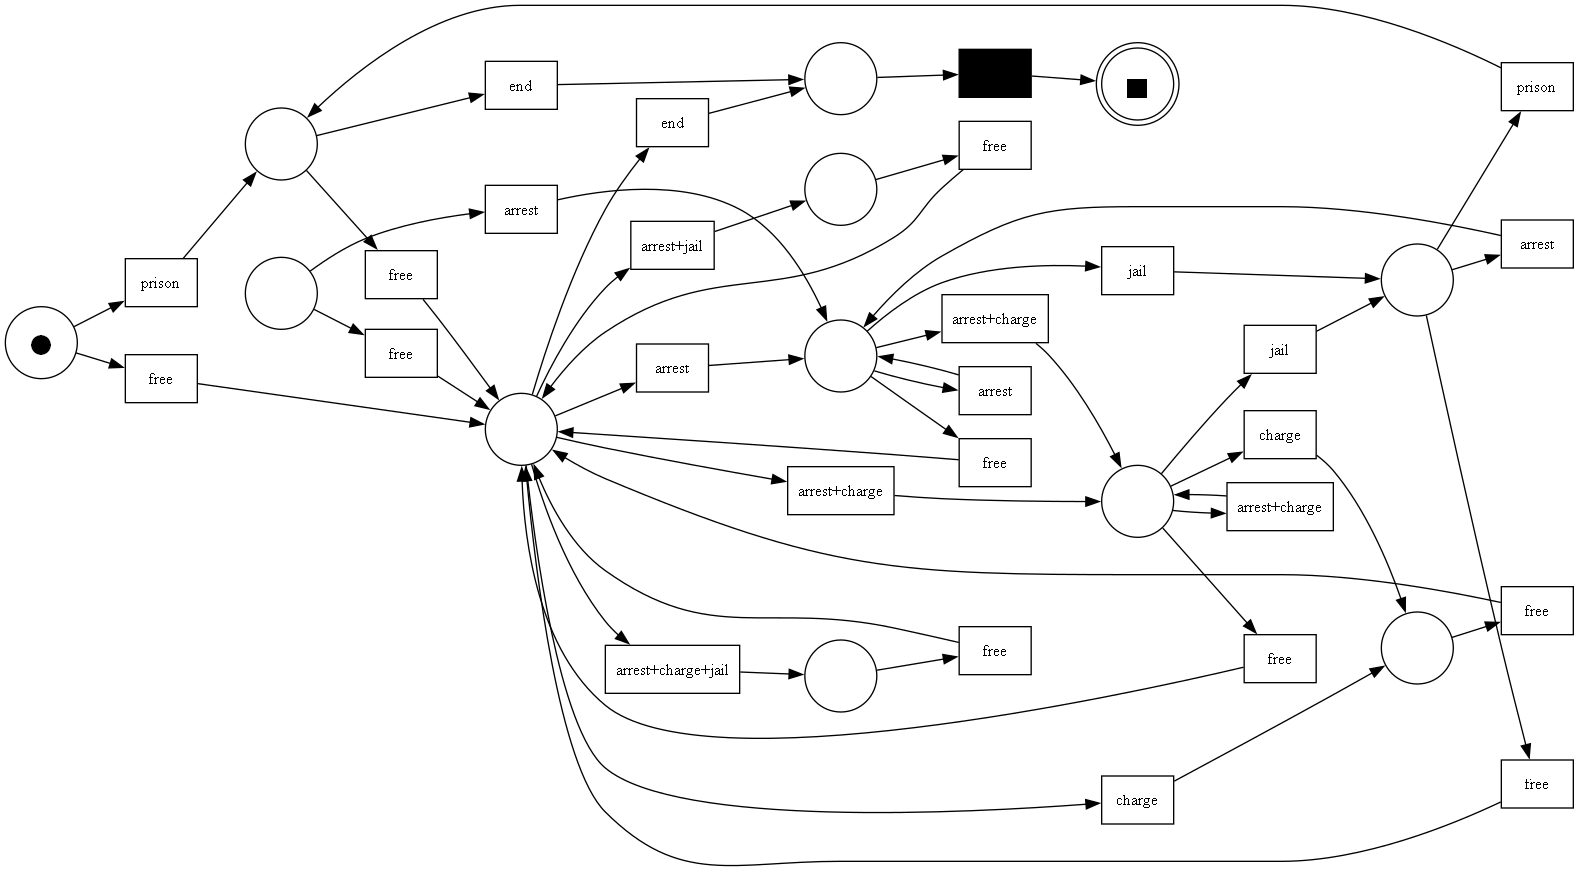

HM_dep0.95


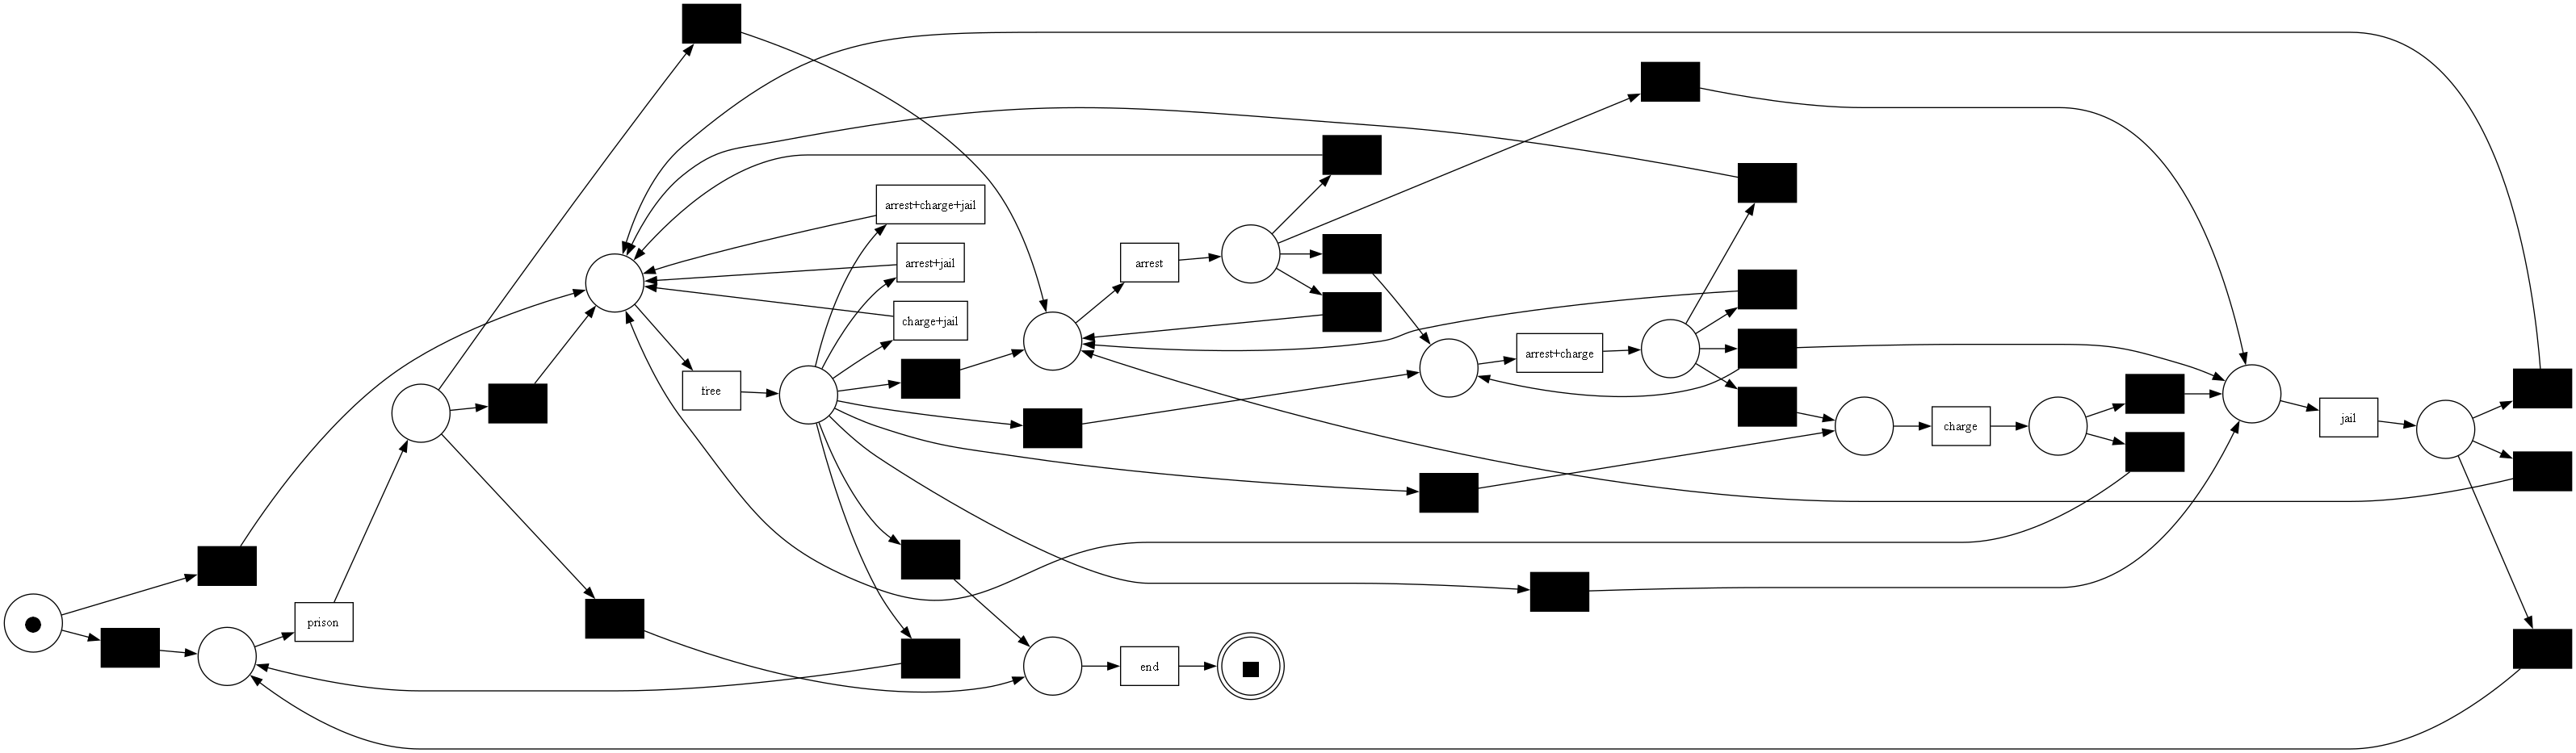

SplitMiner


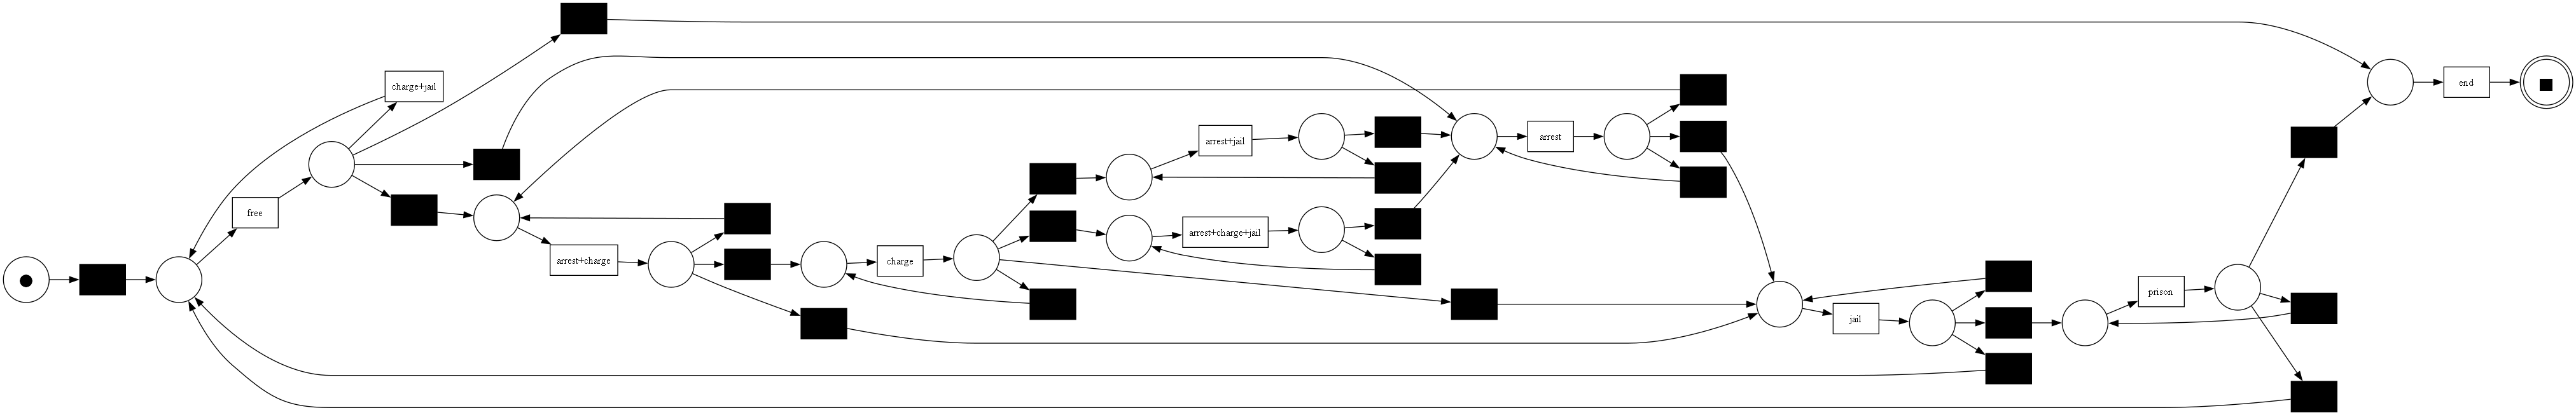

IM_noise0.2


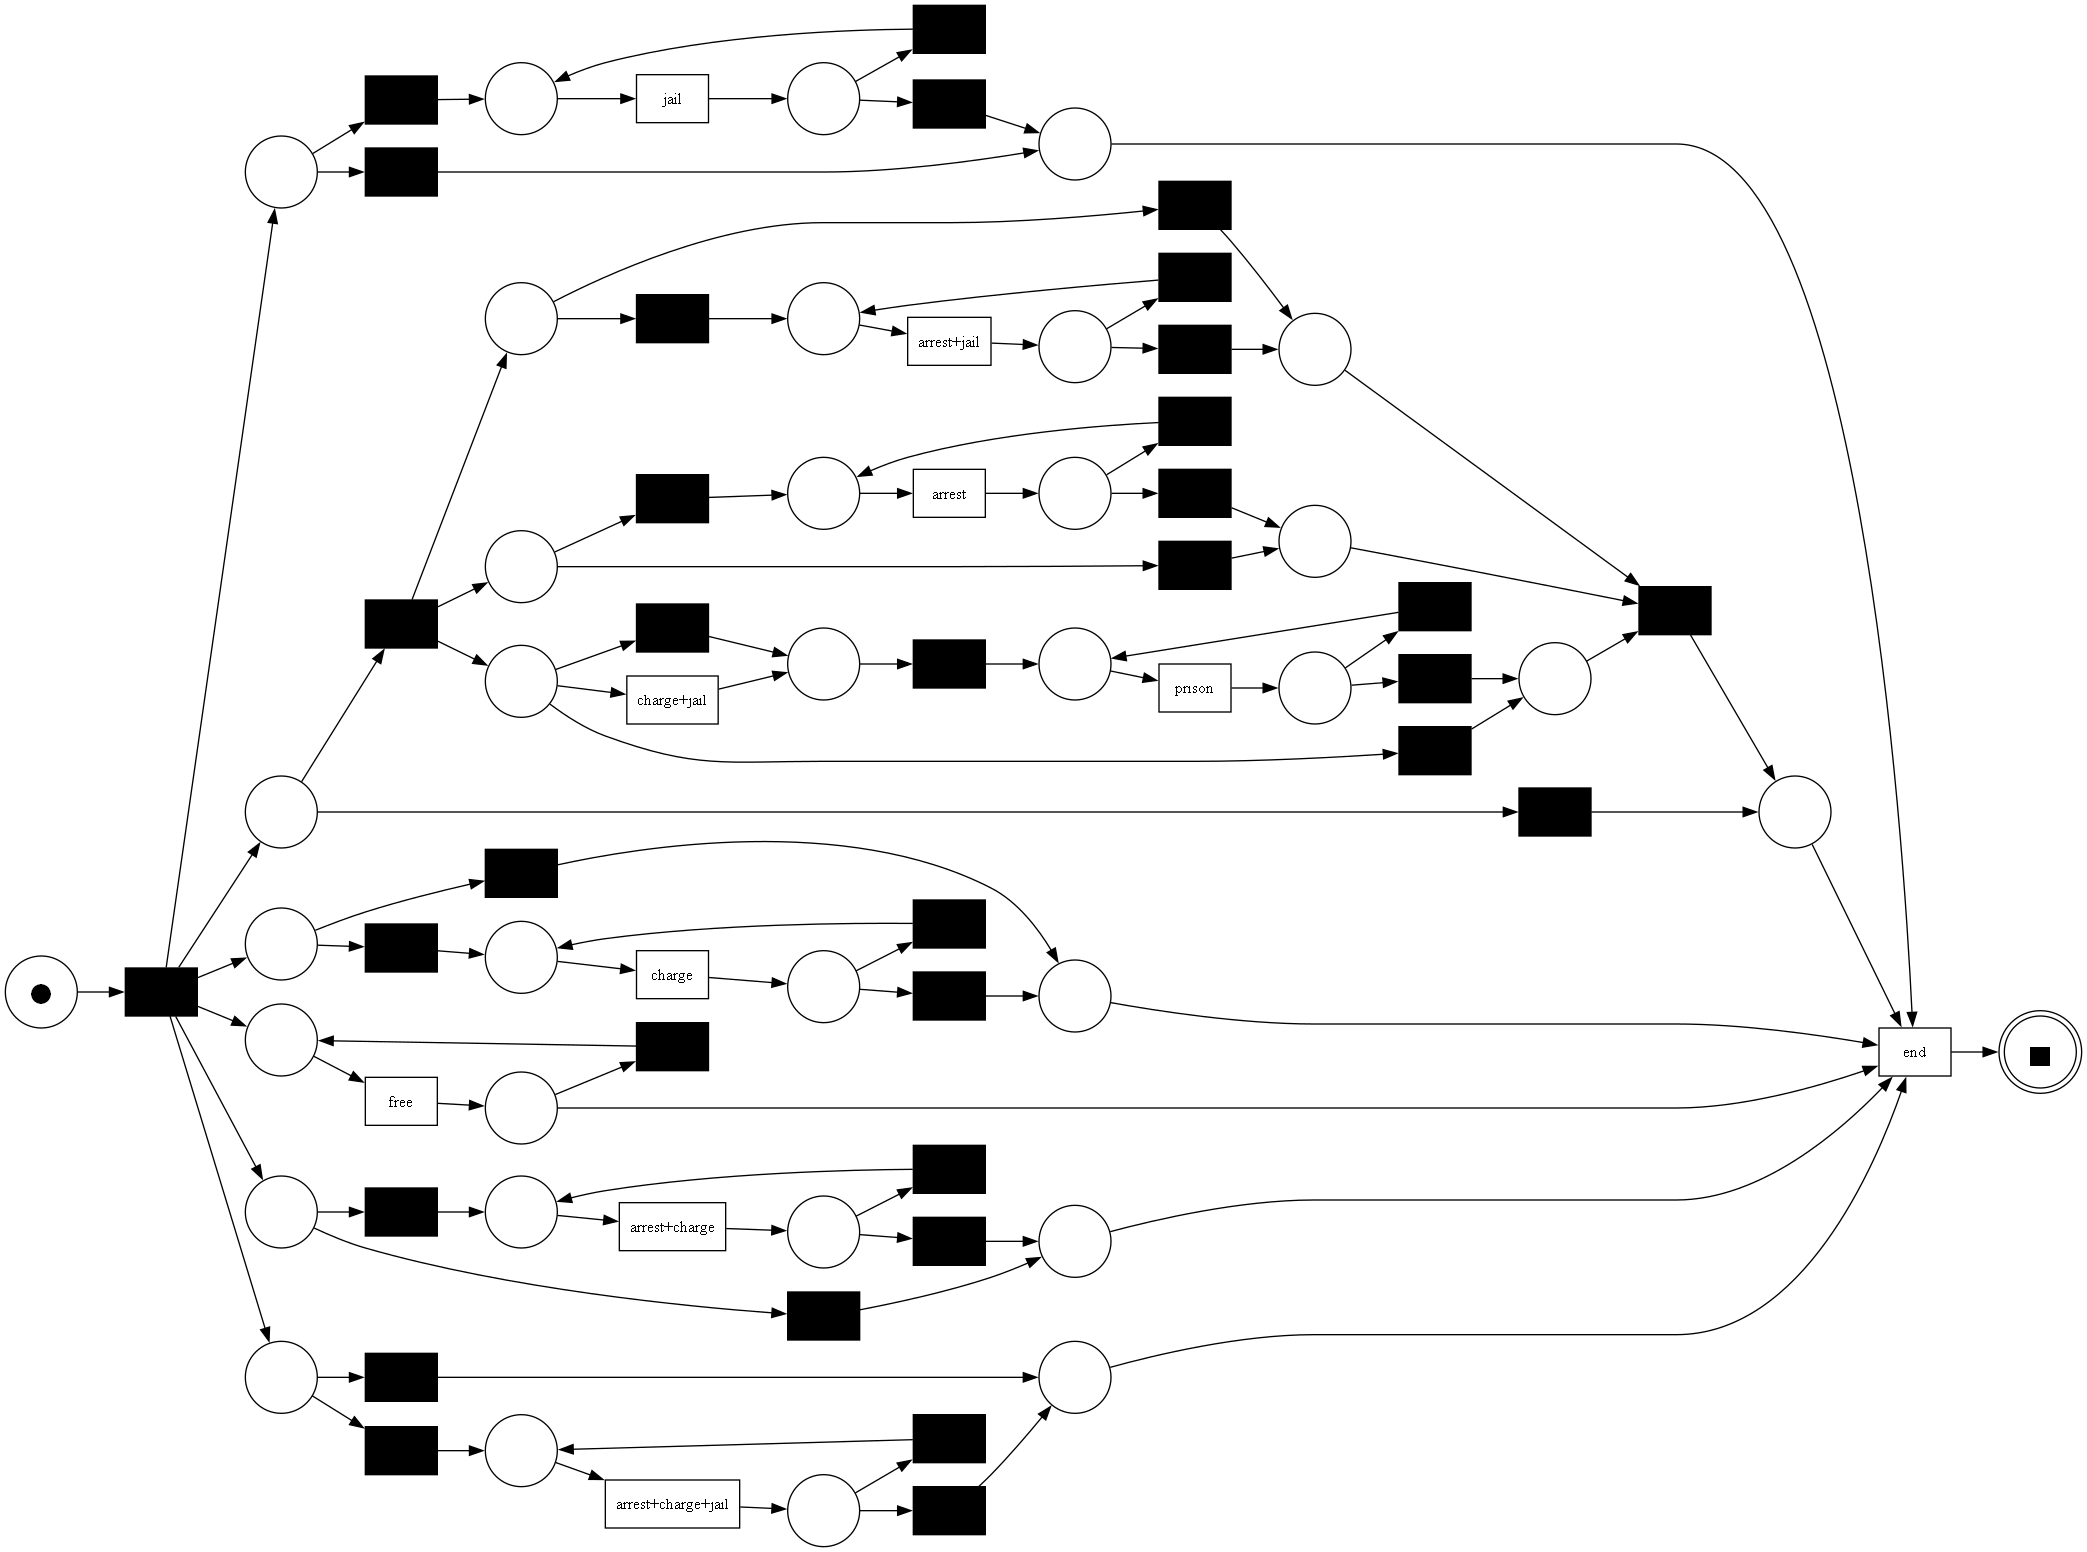

DFG, частоты (весь журнал v2)


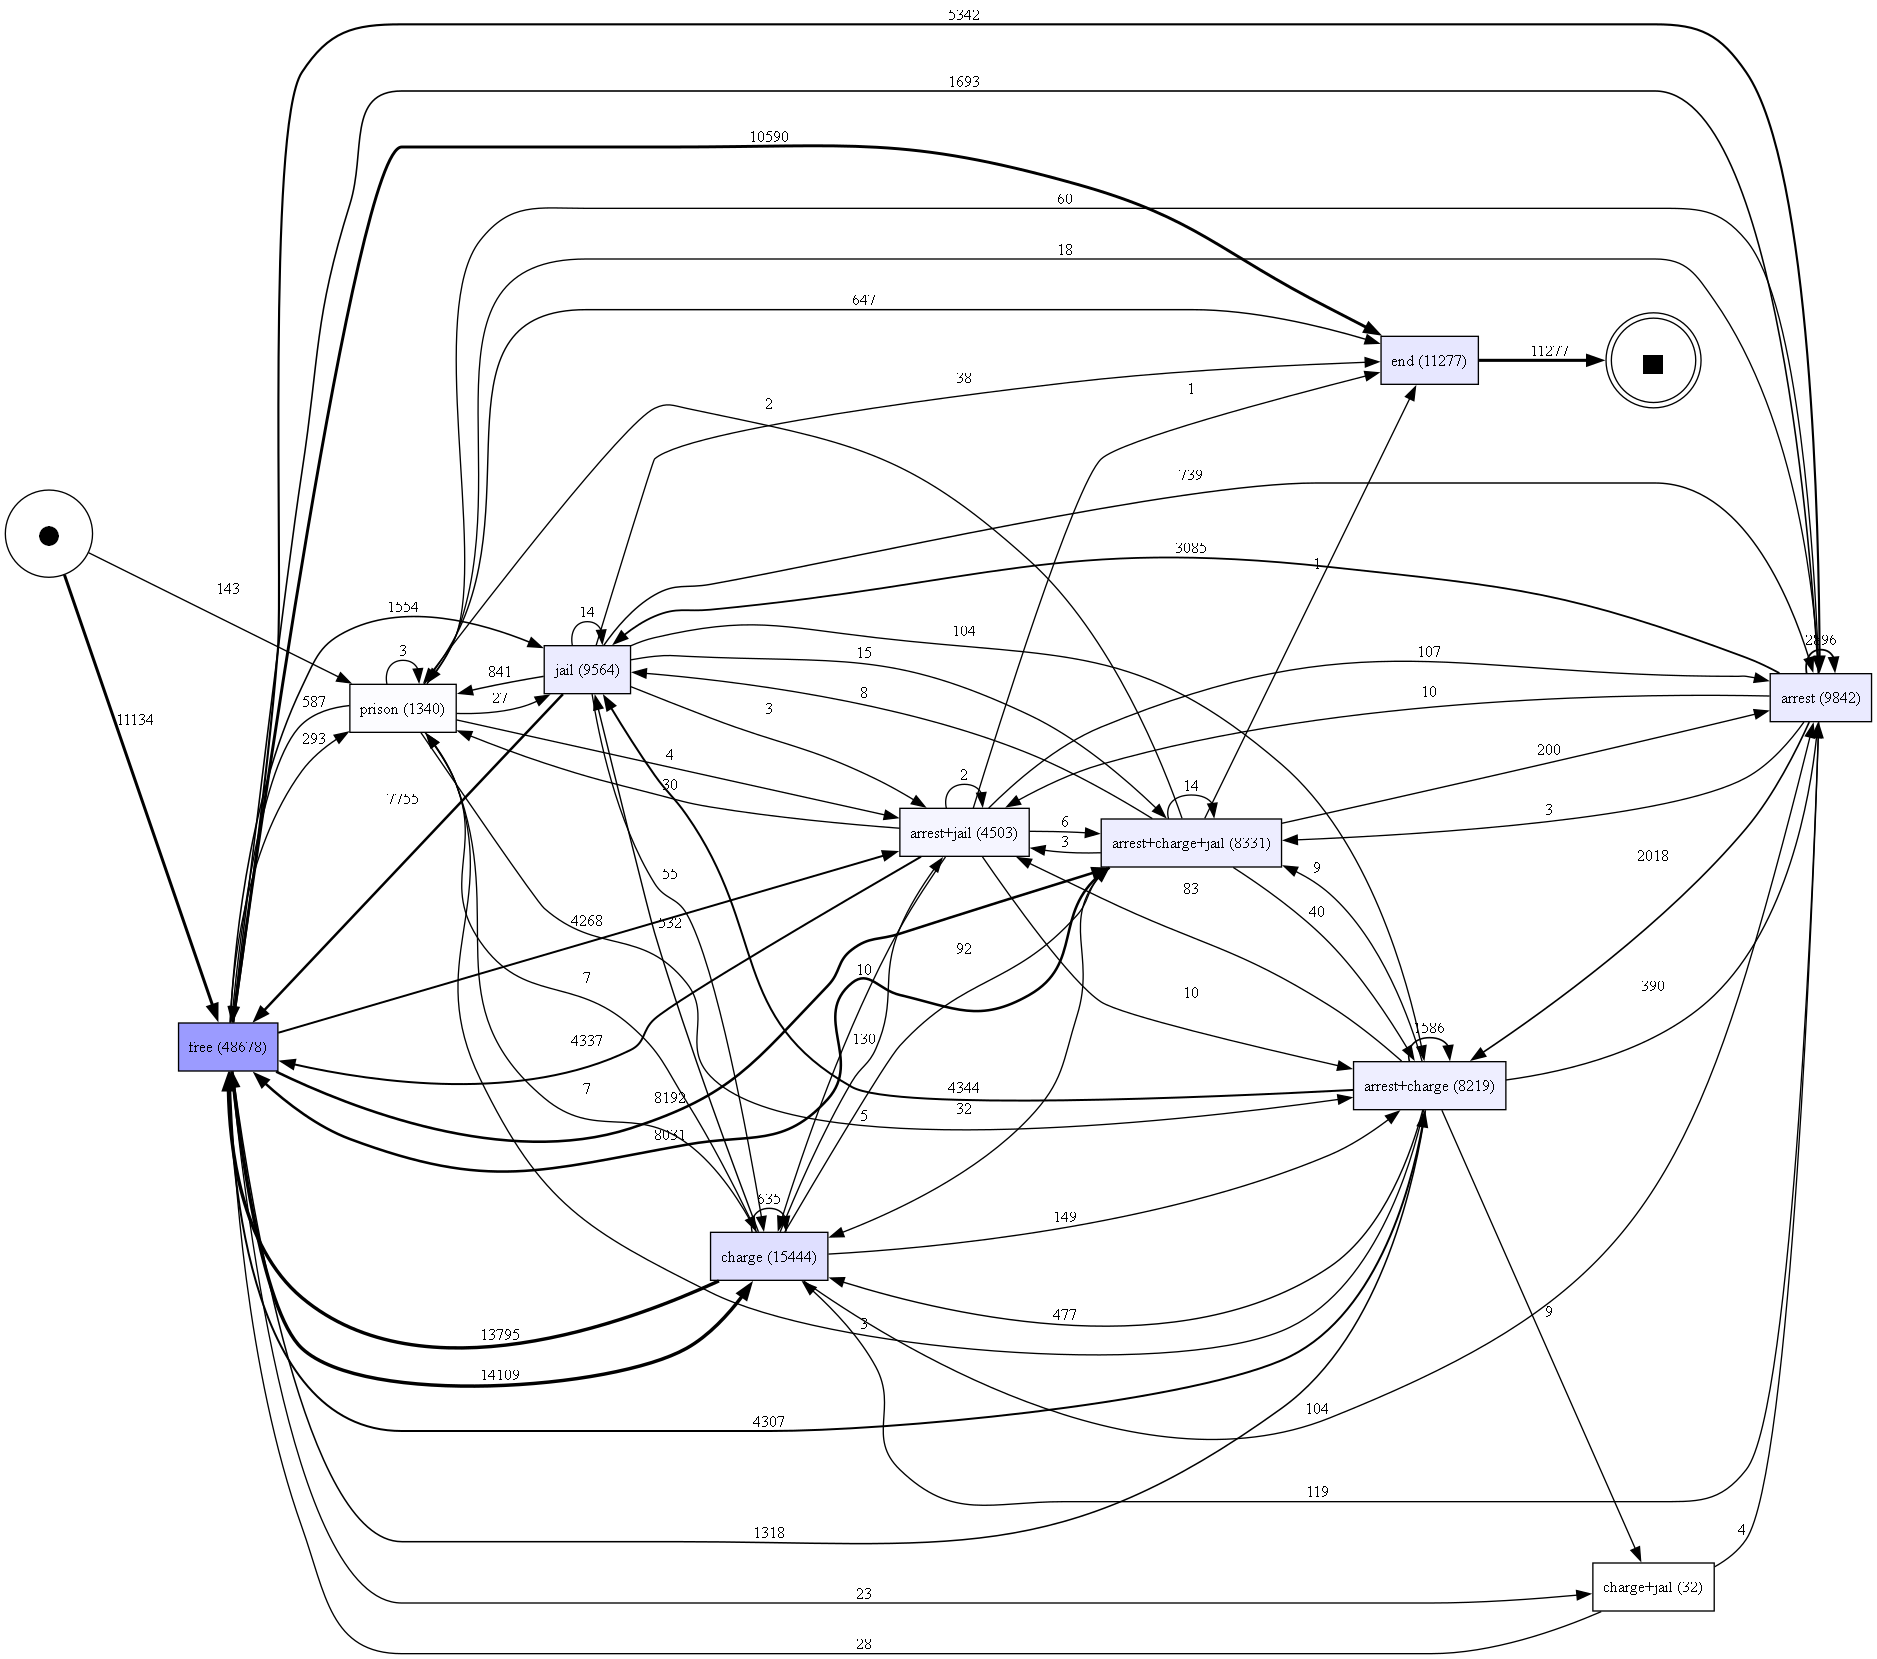

In [9]:
for m in BEST[1:]:
    p = V2 / f"net_{m}.png"
    if p.exists():
        print(m)
        display(Image(filename=str(p), width=1000))
p = V2 / "dfg_frequency.png"
if p.exists():
    print("DFG, частоты (весь журнал v2)")
    display(Image(filename=str(p), width=1000))

## 6. Выводы (окно 2013, версия 2)

**Изменения правил на метриках почти не сказались.** У лучших моделей fitness и precision на test
сдвинулись не больше чем на 0.006, порядок моделей тот же:

| Модель | F1 TBR v1 | F1 TBR v2 |
|---|---|---|
| **DFG p0.05** | 0.850 | **0.849** |
| Split Miner | 0.774 | 0.775 |
| HM 0.95 | 0.747 | 0.745 |
| IM 0.2 | 0.544 | 0.538 |

- **Лучшая модель — по-прежнему DFG p0.05**: fitness на test 0.968, precision 0.756 (нормированная 0.624).
- Переобучения нет: fitness на train и test различается не больше чем на 0.003.
- IM 0 / 0.2, POWL и DFG без фильтра по precision почти не отличаются от цветочной сети; Alpha / Alpha+ непригодны.

**Что дало каждое изменение:**
- `LONG` = 180: составных состояний 12 806 (было 13 228) — 422 эпизода от 180 до 365 дней теперь `дело → заключение`;
- новое правило `end`: две трассы заканчиваются составным состоянием (`arrest+jail`, `arrest+charge+jail`)
  без лишнего возврата в `jail`; из ареста/обвинения напрямую в `end` — **ни одной трассы**:
  последняя запись arrest/charge в базе — 30.03.2016, а конец наблюдения (19.04.2016) задают выходы из заключения,
  поэтому дел в последние два дня нет.